# Token recommendation on 28 days: does the two-week result hold up?

[Notebook 05](05_pool_recommendation_data_and_baseline.ipynb) studied next-token recommendation on 14 days
of swaps and found that a blend of popularity and item nearest neighbours beats the popularity baseline.
This notebook repeats that study on **28 days**: the same 14 days plus the 14 days before them.

**Nothing was re-tuned.** The preprocessing, the models and every setting (50 neighbours, shrinkage 10,
rank 32, blend weights 85% and 50%) are those of notebook 05. What changes:

- **Window:** blocks 25,948,800 to 26,150,399, 10 September to 8 October 2026.
- **Evaluation points:** 21 development points (after day 4, 5, ... 24) in place of 7. The last seven are
  the points of notebook 05, now with 14 more days of history. **The first 14 were never scored before**,
  so they are an honest check of settings that were picked on the other seven.
- **Test point:** after day 26, the same two calendar days as in notebook 05. Only the baselines are scored
  there, as before.

**Short answer.**

| Claim of the two-week study | On 28 days |
| --- | --- |
| Popularity recovers about 16% of first-time tokens, and the level swings with the period | **Holds.** 0.147 on average, between 0.106 and 0.202. |
| Popularity blended with nearest neighbours beats popularity consistently | **Holds, with a smaller gain.** +0.034 in place of +0.051, ahead at 19 of 21 points (12 of the 14 new ones). |
| Nearest neighbours alone are level with popularity | **Does not hold.** They are below it: 0.130 against 0.147. |
| Recency does not reliably help | **Does not hold.** Popularity of the last day beats popularity of the whole history at 16 of 21 points. |

The conclusions are also in [`research/token_recommendation_28_days.md`](../../research/token_recommendation_28_days.md).

**Running time.** The two added weeks take about an hour to download through free public endpoints, and
the tokens of the new pools about ten minutes. With the data in place the notebook runs in about 15 minutes.

In [1]:
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest

sys.path.append("../scripts")
import dex_swaps as ds
import pool_recsys as pr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_rows", 60, "display.float_format", "{:,.3f}".format)

WEEK = 50_400                                    # blocks in seven days
DAY = 7_200
START = 25_948_800                               # 10 September 2026
END = START + 4 * WEEK                           # exclusive; 8 October 2026
FIRST_STUDY_START = START + 2 * WEEK             # where the two-week study (notebook 05) started
TRAIN_END = START + 24 * DAY                     # train: first 24 days
DEV_END = START + 26 * DAY                       # dev: days 25 and 26; test: days 27 and 28
DEV_ORIGINS = [START + d * DAY for d in range(4, 25)]   # rolling evaluation points inside train and dev
TEST_ORIGIN = DEV_END                            # the same calendar point as the test point of notebook 05
FRESH_ORIGINS = [o for o in DEV_ORIGINS if o < FIRST_STUDY_START + 4 * DAY]   # after day 4 ... 17: not scored before
SEEN_ORIGINS = [o for o in DEV_ORIGINS if o >= FIRST_STUDY_START + 4 * DAY]   # after day 18 ... 24: the seven points of notebook 05
HORIZON = 2 * DAY                                # a recommendation is judged on the following two days
K = 10                                           # length of a recommendation list
BASE_SHARE = 0.10                                # a token traded by more than this share of users is a base currency

# Chart style: one fixed colour per series, thin lines, quiet grid.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 90, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 1.4, "legend.frameon": False, "font.size": 9.5,
})

## 1. Data

**Source.** The same as in notebook 05: every `Swap` event of Uniswap V2 and V3 style pools on Ethereum,
with the account that signed the transaction, from free public endpoints (`ds.download_window`), and the two
tokens of every pool (`ds.load_pool_tokens`). The two earlier weeks were downloaded for this notebook.

,value
swaps,5730197
transactions,4060737
signing accounts (users),368305
pools,38381
first swap,2026-09-10 18:31
last swap,2026-10-08 21:34
share of blocks with a swap %,99.396
duplicate events,0
missing values,0
pools whose tokens could be read,38368


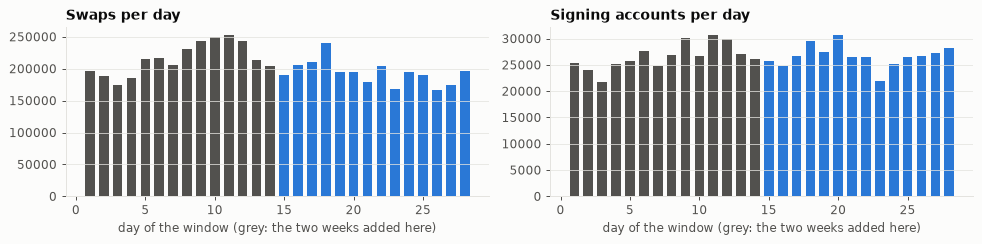

,swaps,transactions,users,pools,lowest daily swaps,highest daily swaps
week,,,,,,
1,1383084,961513,114374,19559,174444,216977
2,1636973,1133613,127841,21809,204976,252492
3,1415898,1025366,125667,16578,178813,240662
4,1294242,940245,118537,18514,166441,204186


In [2]:
DOWNLOADS = [(START, 2 * WEEK), (FIRST_STUDY_START, WEEK), (FIRST_STUDY_START + WEEK, WEEK)]   # the windows as they were downloaded
for first, n_blocks in DOWNLOADS:
    if not all((ds.DATA_DIR / "chunks" / f"swaps_{a}_{b}.parquet").exists() for a, b in ds.chunk_ranges(first, n_blocks)):
        ds.download_window(first, n_blocks)      # resumable; restart it if the free endpoint reports a rate limit

swaps = ds.load_swaps()
swaps = swaps[(swaps["block"] >= START) & (swaps["block"] < END)].reset_index(drop=True)
pool_tokens = ds.load_pool_tokens(swaps["pool"].value_counts().index.tolist())   # cached after the first run

known_pools = set(pool_tokens.dropna()["pool"])
checks = pd.Series({
    "swaps": len(swaps), "transactions": swaps["tx_hash"].nunique(), "signing accounts (users)": swaps["tx_from"].nunique(),
    "pools": swaps["pool"].nunique(),
    "first swap": swaps["timestamp"].min().strftime("%Y-%m-%d %H:%M"), "last swap": swaps["timestamp"].max().strftime("%Y-%m-%d %H:%M"),
    "share of blocks with a swap %": 100 * swaps["block"].nunique() / (END - START),
    "duplicate events": int(swaps.duplicated(["tx_hash", "log_index"]).sum()), "missing values": int(swaps.isna().sum().sum()),
    "pools whose tokens could be read": len(known_pools), "pools that did not answer": int(pool_tokens["token0"].isna().sum()),
    "share of swaps on pools with known tokens %": 100 * swaps["pool"].isin(known_pools).mean(),
    "distinct tokens": pd.concat([pool_tokens["token0"], pool_tokens["token1"]]).nunique(),
}, name="value")
display(checks.to_frame())

swaps = swaps[["block", "timestamp", "tx_hash", "tx_from", "pool", "amount0"]]   # all that is needed below
daily = swaps.groupby((swaps["block"] - START) // DAY + 1).agg(swaps=("tx_hash", "size"), transactions=("tx_hash", "nunique"), users=("tx_from", "nunique"))
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
for ax, column, title in zip(axes, ["swaps", "users"], ["Swaps per day", "Signing accounts per day"]):
    ax.bar(daily.index, daily[column], color=[MUTED if day <= 14 else BLUE for day in daily.index], width=0.7)
    ax.set_xlabel("day of the window (grey: the two weeks added here)"); ax.set_title(title); ax.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()
weekly = swaps.groupby((swaps["block"] - START) // WEEK + 1).agg(swaps=("tx_hash", "size"), transactions=("tx_hash", "nunique"), users=("tx_from", "nunique"), pools=("pool", "nunique"))
weekly.index.name = "week"
weekly.assign(**{"lowest daily swaps": daily["swaps"].groupby((daily.index - 1) // 7 + 1).min(), "highest daily swaps": daily["swaps"].groupby((daily.index - 1) // 7 + 1).max()})

**Validation.** The four weeks are complete (99.4% of blocks have a swap), with no duplicates and no missing
values. The tokens of 38,368 of the 38,381 pools could be read, covering 99.99% of the swaps.

**Size.** 5.7 million swaps in 4.1 million transactions by 368,305 accounts: a little more than twice the
two-week data. The added weeks (grey) are slightly busier than the original two, and no day stands out.

## 2. Preprocessing

Unchanged from notebook 05: every transaction is reduced to the tokens its sender ended up buying and
selling, pass-through tokens are dropped, and tokens traded by more than 10% of the train-period users are
removed as base currencies.

In [3]:
def period(frame, first, last):
    return frame[(frame["block"] >= first) & (frame["block"] < last)]

def base_tokens(frame):
    # Tokens traded by more than BASE_SHARE of the users of `frame`.
    share = frame.groupby("token")["user"].nunique().sort_values(ascending=False) / frame["user"].nunique()
    return share[share > BASE_SHARE]

legs = pr.trade_legs(swaps, pool_tokens)
reduced_share = 100 * legs["tx_hash"].nunique() / swaps["tx_hash"].nunique()
base_share = base_tokens(period(legs, START, TRAIN_END))               # decided on the train period only
BASE_TOKENS = list(base_share.index)
other_cuts = {"first 4 days": period(legs, START, START + 4 * DAY), "first 10 days of notebook 05": period(legs, FIRST_STUDY_START, FIRST_STUDY_START + 10 * DAY)}
print("Base currencies (share of train-period users who traded them):", {t[:10] + "…": round(s, 2) for t, s in base_share.items()})
print("Same list from other cuts:", {name: set(base_tokens(frame).index) == set(BASE_TOKENS) for name, frame in other_cuts.items()})
legs = legs[~legs["token"].isin(BASE_TOKENS)].reset_index(drop=True)
events = swaps[["block", "tx_from", "pool"]].rename(columns={"tx_from": "user"})   # pool-level interactions, for section 5

def token_stats(frame):
    token_users, user_tokens = frame.groupby("token")["user"].nunique(), frame.groupby("user")["token"].nunique()
    return {
        "users with at least one non-base token": len(user_tokens), "non-base tokens": len(token_users),
        "distinct user-token pairs": len(frame.drop_duplicates(["user", "token"])),
        "median tokens per user": user_tokens.median(), "users with one token %": 100 * (user_tokens == 1).mean(),
        "users with at least 2 tokens": int((user_tokens >= 2).sum()), "users with at least 5 tokens": int((user_tokens >= 5).sum()),
        "tokens with at least 5 users": int((token_users >= 5).sum()), "tokens with at least 100 users": int((token_users >= 100).sum()),
        "share of buys among the legs %": 100 * (frame["side"] == "buy").mean(),
    }

print(f"transactions reduced to at least one bought or sold token: {reduced_share:.1f}%")
pd.DataFrame({"28 days": token_stats(legs), "first 14 days (new)": token_stats(period(legs, START, FIRST_STUDY_START)),
              "last 14 days (notebook 05)": token_stats(period(legs, FIRST_STUDY_START, END))})

Base currencies (share of train-period users who traded them): {'0xc02aaa39…': 0.83, '0xa0b86991…': 0.42, '0xdac17f95…': 0.31}


Same list from other cuts: {'first 4 days': True, 'first 10 days of notebook 05': True}


transactions reduced to at least one bought or sold token: 97.1%


,28 days,first 14 days (new),last 14 days (notebook 05)
users with at least one non-base token,"264,227.000","147,506.000","157,060.000"
non-base tokens,"31,759.000","22,804.000","19,631.000"
distinct user-token pairs,"752,493.000","426,016.000","419,948.000"
median tokens per user,1.000,1.000,1.000
users with one token %,68.770,68.939,69.897
users with at least 2 tokens,"82,519.000","45,817.000","47,280.000"
users with at least 5 tokens,"19,793.000","11,039.000","11,000.000"
tokens with at least 5 users,"8,089.000","5,338.000","4,655.000"
tokens with at least 100 users,941.000,657.000,606.000
share of buys among the legs %,51.764,51.632,51.909


- **The base currencies are the same three tokens** (wrapped ETH and the two large dollar stablecoins),
  whichever period decides the list.
- **The two halves look alike.** Each has about 150,000 users, about 20,000 tokens and about 11,000 users
  with five or more tokens. 69% of users trade a single token in either half and in the whole.
- **Doubling the window does not double the users with a history.** Users with at least five tokens go
  from 11,000 to 19,800. Tokens with at least five users go from about 5,000 to 8,100.
- **Few accounts come back.** The halves have 147,506 and 157,060 users and the whole 264,227, so only
  about 40,000 accounts are active in both.

## 3. The split

One global timeline, as before. At each evaluation point everything earlier (from day 1) is the history and
the next two days are the target. The table lists the 21 development points and the test point.

In [4]:
def make_task(origin, frame=None, item="token", future_side=None, history_start=START):
    # Everything from `history_start` up to `origin` is history; the following two days are the target.
    frame = legs if frame is None else frame
    future = period(frame, origin, origin + HORIZON)
    if future_side:
        future = future[future["side"] == future_side]
    history = pr.interactions(period(frame, history_start, origin), "user", item)
    task = pr.build_task(history, pr.interactions(future, "user", item))
    recent = pr.to_matrix(pr.interactions(period(frame, origin - DAY, origin), "user", item), task["users"], task["items"])
    return {"task": task, "history": history, "recent": recent}

ORIGINS = DEV_ORIGINS + [TEST_ORIGIN]
day_of = lambda origin: (origin - START) // DAY
point = lambda origin: f"after day {day_of(origin)}"
start = time.time()
setups = {origin: make_task(origin) for origin in ORIGINS}
print(f"{time.time() - start:.0f}s")

blocks, times = swaps["block"].to_numpy(), swaps["timestamp"]
rows = {}
for origin in ORIGINS:
    task = setups[origin]["task"]
    users = task["eval_users"]
    new_warm, cold = int(task["new"][users].sum()), int(task["cold_new"][users].sum())
    rows[point(origin)] = {
        "use": "test" if origin == TEST_ORIGIN else "development",
        "scored in notebook 05": "yes" if origin in SEEN_ORIGINS or origin == TEST_ORIGIN else "no",
        "history ends": times.iloc[np.searchsorted(blocks, origin) - 1].strftime("%m-%d %H:%M"),
        "users in history": len(task["users"]), "tokens in history": len(task["items"]),
        "users evaluated": len(users), "new pairs to predict": new_warm + cold,
        "of which tokens absent from the history %": 100 * cold / (new_warm + cold),
        "repeat pairs of these users": int(task["repeat"][users].sum()),
    }
origin_table = pd.DataFrame(rows).T

# Save the interactions with their period (data/ is ignored by git).
legs.assign(split=np.select([legs["block"] < TRAIN_END, legs["block"] < DEV_END], ["train", "dev"], "test")).to_parquet(ds.DATA_DIR / "token_legs_28_days_with_split.parquet")
origin_table

22s


,use,scored in notebook 05,history ends,users in history,tokens in history,users evaluated,new pairs to predict,of which tokens absent from the history %,repeat pairs of these users
after day 4,development,no,09-14 18:50,48870,10142,6280,29363,23.765,20927
after day 5,development,no,09-15 18:57,59003,12668,6403,27045,21.841,22043
after day 6,development,no,09-16 19:02,68777,13971,6520,27565,19.528,21302
after day 7,development,no,09-17 19:07,77643,14865,7631,30706,22.790,23819
after day 8,development,no,09-18 19:11,87597,15647,8320,34519,30.963,25645
after day 9,development,no,09-19 19:18,100221,16361,8803,33888,25.927,27435
after day 10,development,no,09-20 19:24,109376,19609,9022,29646,16.883,28023
after day 11,development,no,09-21 19:34,119908,20543,8499,27057,14.721,29071
after day 12,development,no,09-22 19:45,130170,21664,8180,25032,13.051,27236
after day 13,development,no,09-23 19:56,138882,22408,8304,23876,13.093,24584


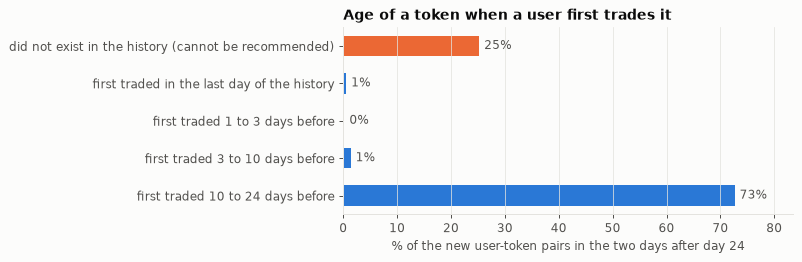

{'did not exist in the history (cannot be recommended)': 25.2, 'first traded in the last day of the history': 0.5, 'first traded 1 to 3 days before': 0.2, 'first traded 3 to 10 days before': 1.4, 'first traded 10 to 24 days before': 72.6}
22,769 new pairs; the 10 most picked tokens account for 15% of them, the 100 most picked for 39%


In [5]:
# How old is a token when a user picks it up for the first time? (last development origin)
last = setups[DEV_ORIGINS[-1]]
task, history = last["task"], last["history"]
first_seen = history.groupby("item")["first_block"].min()
new = task["new"][task["eval_users"]].tocoo()
age_days = (DEV_ORIGINS[-1] - first_seen.reindex(task["items"][new.col]).to_numpy()) / DAY
buckets = pd.Series({
    "did not exist in the history (cannot be recommended)": int(task["cold_new"][task["eval_users"]].sum()),
    "first traded in the last day of the history": int((age_days <= 1).sum()),
    "first traded 1 to 3 days before": int(((age_days > 1) & (age_days <= 3)).sum()),
    "first traded 3 to 10 days before": int(((age_days > 3) & (age_days <= 10)).sum()),
    "first traded 10 to 24 days before": int((age_days > 10).sum()),
})
share = 100 * buckets / buckets.sum()

fig, ax = plt.subplots(figsize=(9, 3.0))
ax.barh(np.arange(len(share)), share.to_numpy(), color=[ORANGE, BLUE, BLUE, BLUE, BLUE], height=0.55)
ax.set_yticks(np.arange(len(share))); ax.set_yticklabels(share.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
for y, value in enumerate(share):
    ax.annotate(f"{value:.0f}%", (value, y), xytext=(4, 0), textcoords="offset points", va="center", color=MUTED)
ax.set_xlim(0, share.max() * 1.15)
ax.set_xlabel("% of the new user-token pairs in the two days after day 24"); ax.set_title("Age of a token when a user first trades it")
fig.tight_layout(); plt.show()
top = pd.Series(task["items"][new.col]).value_counts()
print(share.round(1).to_dict())
print(f"{buckets.sum():,} new pairs; the 10 most picked tokens account for {100 * top.iloc[:10].sum() / buckets.sum():.0f}% of them, the 100 most picked for {100 * top.iloc[:100].sum() / buckets.sum():.0f}%")

**What the longer window shows about the task.**

- **About 8,300 users are evaluated per point** (6,300 to 10,000), a little more than in two weeks.
- **The share of tokens that cannot be recommended varies more than two weeks suggested:** from 10% to 31%
  of the new pairs, against 15 to 25% before. It is the share of adoptions that go to tokens launched
  inside the two target days.
- **"At launch or established" is confirmed.** After day 24, a quarter of the new pairs go to tokens that
  did not exist yet and 73% to tokens that had been trading for more than ten days. Only 2% go to tokens
  that appeared in the last ten days of the history.
- **The adoptions stay spread out:** the ten most picked tokens account for 15% of the new pairs and the
  hundred most picked for 39%, as in notebook 05.

## 4. Baseline

Task, metrics and protocol are those of notebook 05: rank the tokens the user has not traded, a hit is a
token traded for the first time in the next two days, recall@10 averaged over users is the main metric, and
all tokens of the history are ranked without sampling. The fixed baseline is popularity over the whole
history.

In [6]:
def recall_and_more(model, task, target="new"):
    result = pr.evaluate(model, task, K, target)
    return result, {"recall@10": result["recall"].mean(), "NDCG@10": result["ndcg"].mean(), "hit rate": result["hit"].mean(),
                    "coverage %": 100 * pr.coverage(result.attrs["recommended"], len(task["items"]))}

def summarize(per_origin):
    # per_origin: {origin: metrics dict}; mean, range over development points, and the test point.
    dev = pd.DataFrame({o: m for o, m in per_origin.items() if o != TEST_ORIGIN}).T
    head = f"development ({len(dev)} points)"
    row = {(head, "recall@10"): dev["recall@10"].mean(),
           (head, "lowest"): dev["recall@10"].min(), (head, "highest"): dev["recall@10"].max(),
           (head, "NDCG@10"): dev["NDCG@10"].mean(), (head, "hit rate"): dev["hit rate"].mean(),
           (head, "coverage %"): dev["coverage %"].mean()}
    if TEST_ORIGIN in per_origin:
        for key in ["recall@10", "NDCG@10", "hit rate"]:
            row[("test (after day 26)", key)] = per_origin[TEST_ORIGIN][key]
    return row

start = time.time()
fitted = {}                                       # models reused in section 5
baseline_metrics = {"Popularity (fixed baseline)": {}, "Recent popularity": {}, "all tokens: Own history": {}, "all tokens: Popularity": {}}
user_noise = {}                                   # half-width of the bootstrap interval over users, per point
for origin in ORIGINS:
    setup = setups[origin]
    task = setup["task"]
    popularity, recent = pr.Popularity().fit(task["history"]), pr.Popularity().fit(setup["recent"])
    fitted[origin] = {"Popularity (fixed baseline)": popularity, "Recent popularity": recent}
    result, baseline_metrics["Popularity (fixed baseline)"][origin] = recall_and_more(popularity, task)
    low, high = pr.bootstrap_mean(result["recall"], n_boot=300)
    user_noise[origin] = (high - low) / 2
    _, baseline_metrics["Recent popularity"][origin] = recall_and_more(recent, task)
    counts_task = {**task, "history": pr.to_matrix(setup["history"], task["users"], task["items"], binary=False)}
    _, baseline_metrics["all tokens: Own history"][origin] = recall_and_more(pr.OwnHistory().fit(counts_task["history"]), counts_task, "all")
    _, baseline_metrics["all tokens: Popularity"][origin] = recall_and_more(popularity, task, "all")
print(f"{time.time() - start:.0f}s")

baseline_table = pd.DataFrame({name: summarize(values) for name, values in baseline_metrics.items()}).T
baseline_table.columns = pd.MultiIndex.from_tuples(baseline_table.columns)
display(baseline_table)

def by_group(per_origin_recall):
    # Mean, lowest and highest recall@10 over the fresh points, the points of notebook 05, and all of them.
    groups = {"14 points not scored before (after day 4 to 17)": FRESH_ORIGINS, "7 points of notebook 05 (after day 18 to 24)": SEEN_ORIGINS, "all 21 development points": DEV_ORIGINS}
    return pd.DataFrame({name: {"mean": np.mean([per_origin_recall[o] for o in origins]), "lowest": min(per_origin_recall[o] for o in origins),
                                "highest": max(per_origin_recall[o] for o in origins)} for name, origins in groups.items()}).T

print("Popularity (fixed baseline), recall@10 by group of evaluation points:")
display(by_group({o: m["recall@10"] for o, m in baseline_metrics["Popularity (fixed baseline)"].items()}))
print(f"Sampling uncertainty over users at one point: ±{np.mean(list(user_noise.values())):.3f} on average (95% bootstrap half-width)")
print("Recall@10 at each evaluation point (new tokens):")
pd.DataFrame({name: {point(o): m["recall@10"] for o, m in baseline_metrics[name].items()} for name in ["Popularity (fixed baseline)", "Recent popularity"]})

94s


development (21 points)                                            test (after day 26)                 
                                          recall@10 lowest highest NDCG@10 hit rate coverage %           recall@10 NDCG@10 hit rate
Popularity (fixed baseline)                   0.147  0.106   0.202   0.093    0.251      0.465               0.154   0.097    0.221
Recent popularity                             0.166  0.099   0.269   0.106    0.276      0.402               0.176   0.099    0.241
all tokens: Own history                       0.260  0.215   0.335   0.261    0.519     16.701               0.261   0.244    0.485
all tokens: Popularity                        0.155  0.122   0.214   0.135    0.373      0.051               0.155   0.129    0.331

Popularity (fixed baseline), recall@10 by group of evaluation points:


,mean,lowest,highest
14 points not scored before (after day 4 to 17),0.148,0.111,0.192
7 points of notebook 05 (after day 18 to 24),0.146,0.106,0.202
all 21 development points,0.147,0.106,0.202


Sampling uncertainty over users at one point: ±0.006 on average (95% bootstrap half-width)
Recall@10 at each evaluation point (new tokens):


,Popularity (fixed baseline),Recent popularity
after day 4,0.192,0.174
after day 5,0.182,0.180
after day 6,0.151,0.162
after day 7,0.120,0.133
after day 8,0.111,0.112
after day 9,0.141,0.143
after day 10,0.144,0.125
after day 11,0.146,0.151
after day 12,0.149,0.186
after day 13,0.127,0.156


### How the baseline performs on 28 days

- **The level is confirmed.** Popularity reaches recall@10 of 0.147 over the 21 points, against 0.155 over
  the seven of notebook 05. On the 14 points never scored before it is 0.148.
- **So is the swing.** The range is 0.106 to 0.202, again many times the sampling uncertainty over users
  at one point (±0.006).
- **Recency helps more than two weeks suggested.** Popularity of the last day is ahead at 16 of the 21
  points and by 0.019 on average (0.166). Much of that comes from four points: after day 15, 16, 17 and 24 it
  is ahead by 0.06 to 0.10, and at most other points the two are close. Notebook 05 saw seven points and judged the
  difference unreliable.
- **A longer history does not make popularity better.** At the test point popularity over 26 days scores
  0.154; notebook 05 scored 0.202 at the same point with a 12-day history. The targets are not identical,
  because a longer history leaves fewer tokens that are new to a user, but it points the same way as the
  previous item: what was popular three weeks ago is a weak guide.
- **Coverage stays negligible** (under 0.5% of the tokens), and with repeats counted a user's own history
  is again far ahead of popularity.

## 5. Method fit: the candidates of notebook 05, unchanged

In [7]:
start = time.time()
candidate_recall, pooled = {}, {}
for origin in DEV_ORIGINS:
    task = setups[origin]["task"]
    popularity, recent = fitted[origin]["Popularity (fixed baseline)"], fitted[origin]["Recent popularity"]
    knn = pr.ItemKNN(k=50, shrink=10).fit(task["history"])
    models = {
        "Popularity (fixed baseline)": popularity,
        "Recent popularity": recent,
        "Item nearest neighbours": knn,
        "Truncated SVD, rank 32": pr.PureSVD(rank=32).fit(task["history"]),
        "Blend: 85% popularity + neighbours": pr.Blend(popularity, knn, 0.85),
        "Blend: 50% popularity + neighbours": pr.Blend(popularity, knn, 0.5),
        "Blend: 85% recent popularity + neighbours": pr.Blend(recent, knn, 0.85),
    }
    for name, model in models.items():
        result, metrics = recall_and_more(model, task)
        candidate_recall.setdefault(name, {})[point(origin)] = metrics
        part = result[["recall", "n_history"]].copy()
        part.attrs = {}                      # drop the attached lists so that the parts can be concatenated
        pooled.setdefault(name, []).append(part)
print(f"{time.time() - start:.0f}s")

per_point = pd.DataFrame({name: {p: m["recall@10"] for p, m in values.items()} for name, values in candidate_recall.items()}).T
base = per_point.loc["Popularity (fixed baseline)"]
fresh, seen = [point(o) for o in FRESH_ORIGINS], [point(o) for o in SEEN_ORIGINS]

def summary_of(columns):
    part, reference = per_point[columns], base[columns]
    return pd.DataFrame({
        "mean recall@10": part.mean(axis=1), "lowest": part.min(axis=1), "highest": part.max(axis=1),
        "mean difference from baseline": (part - reference).mean(axis=1),
        f"points where it beats the baseline (of {len(columns)})": part.gt(reference, axis=1).sum(axis=1),
        "mean coverage %": pd.Series({name: np.mean([values[p]["coverage %"] for p in columns]) for name, values in candidate_recall.items()}),
    })

print("All 21 development points:")
display(summary_of(list(per_point.columns)))
print("The 14 points not scored before (after day 4 to 17). No setting was chosen with these:")
display(summary_of(fresh))
print("The 7 points of notebook 05 (after day 18 to 24), now with 14 more days of history:")
display(summary_of(seen))
print("Recall@10 at each development point:")
per_point.T

191s
All 21 development points:


,mean recall@10,lowest,highest,mean difference from baseline,points where it beats the baseline (of 21),mean coverage %
Popularity (fixed baseline),0.147,0.106,0.202,0.000,0,0.465
Recent popularity,0.166,0.099,0.269,0.019,16,0.402
Item nearest neighbours,0.130,0.092,0.192,-0.017,6,16.849
"Truncated SVD, rank 32",0.121,0.083,0.199,-0.026,3,3.461
Blend: 85% popularity + neighbours,0.166,0.117,0.221,0.019,21,0.527
Blend: 50% popularity + neighbours,0.181,0.133,0.252,0.034,19,12.847
Blend: 85% recent popularity + neighbours,0.186,0.109,0.287,0.039,20,0.744


The 14 points not scored before (after day 4 to 17). No setting was chosen with these:


,mean recall@10,lowest,highest,mean difference from baseline,points where it beats the baseline (of 14),mean coverage %
Popularity (fixed baseline),0.148,0.111,0.192,0.000,0,0.489
Recent popularity,0.170,0.112,0.269,0.022,11,0.438
Item nearest neighbours,0.125,0.092,0.192,-0.022,4,18.669
"Truncated SVD, rank 32",0.114,0.083,0.147,-0.034,0,3.811
Blend: 85% popularity + neighbours,0.169,0.137,0.216,0.021,14,0.559
Blend: 50% popularity + neighbours,0.176,0.133,0.252,0.029,12,14.469
Blend: 85% recent popularity + neighbours,0.188,0.135,0.287,0.040,13,0.535


The 7 points of notebook 05 (after day 18 to 24), now with 14 more days of history:


,mean recall@10,lowest,highest,mean difference from baseline,points where it beats the baseline (of 7),mean coverage %
Popularity (fixed baseline),0.146,0.106,0.202,0.000,0,0.417
Recent popularity,0.160,0.099,0.213,0.014,5,0.331
Item nearest neighbours,0.141,0.110,0.175,-0.005,2,13.210
"Truncated SVD, rank 32",0.136,0.103,0.199,-0.010,3,2.762
Blend: 85% popularity + neighbours,0.161,0.117,0.221,0.015,7,0.462
Blend: 50% popularity + neighbours,0.190,0.152,0.245,0.044,7,9.603
Blend: 85% recent popularity + neighbours,0.182,0.109,0.264,0.035,7,1.163


Recall@10 at each development point:


,Popularity (fixed baseline),Recent popularity,Item nearest neighbours,"Truncated SVD, rank 32",Blend: 85% popularity + neighbours,Blend: 50% popularity + neighbours,Blend: 85% recent popularity + neighbours
after day 4,0.192,0.174,0.192,0.147,0.211,0.252,0.202
after day 5,0.182,0.180,0.185,0.142,0.210,0.234,0.219
after day 6,0.151,0.162,0.152,0.120,0.187,0.208,0.178
after day 7,0.120,0.133,0.124,0.104,0.150,0.168,0.149
after day 8,0.111,0.112,0.123,0.108,0.137,0.156,0.136
after day 9,0.141,0.143,0.118,0.111,0.161,0.165,0.174
after day 10,0.144,0.125,0.115,0.107,0.156,0.163,0.135
after day 11,0.146,0.151,0.118,0.104,0.158,0.168,0.167
after day 12,0.149,0.186,0.118,0.123,0.175,0.183,0.198
after day 13,0.127,0.156,0.105,0.123,0.157,0.160,0.180


In [8]:
# Is the gain over the baseline more than period noise? Paired by evaluation point.
def paired(name, columns):
    difference = (per_point.loc[name] - base)[columns].to_numpy()
    rng = np.random.default_rng(0)
    means = difference[rng.integers(0, len(difference), (5000, len(difference)))].mean(axis=1)
    wins = int((difference > 0).sum())
    return {"points": len(difference), "wins": wins, "mean difference": difference.mean(), "smallest difference": difference.min(),
            "largest difference": difference.max(), "95% interval of the mean, low": np.quantile(means, 0.025),
            "95% interval of the mean, high": np.quantile(means, 0.975), "sign test p": binomtest(wins, len(difference)).pvalue}

every_second = [point(o) for o in DEV_ORIGINS[::2]]      # targets do not overlap: after day 4, 6, ... 24
tests = {}
for name in ["Blend: 50% popularity + neighbours", "Blend: 85% popularity + neighbours", "Item nearest neighbours", "Recent popularity", "Truncated SVD, rank 32"]:
    tests[(name, "all 21 points")] = paired(name, list(per_point.columns))
    tests[(name, "14 points not scored before")] = paired(name, fresh)
    tests[(name, "11 points with separate targets")] = paired(name, every_second)
pd.DataFrame(tests).T

points   wins  mean difference  smallest difference  largest difference  95% interval of the mean, low  95% interval of the mean, high  sign test p
Blend: 50% popularity + neighbours all 21 points                    21.000 19.000            0.034               -0.005               0.087                          0.024                           0.044        0.000
                                   14 points not scored before      14.000 12.000            0.029               -0.005               0.061                          0.018                           0.040        0.013
                                   11 points with separate targets  11.000 10.000            0.036               -0.004               0.087                          0.022                           0.051        0.012
Blend: 85% popularity + neighbours all 21 points                    21.000 21.000            0.019                0.004               0.036                          0.016                           0.023        0.000
                                   14 points not scored before      14.000 14.000            0.021                0.004               0.036                          0.017                           0.026        0.000
                                   11 points with separate targets  11.000 11.000            0.018                0.004               0.036                          0.014                           0.023        0.001
Item nearest neighbours            all 21 points                    21.000  6.000           -0.017               -0.083               0.055                         -0.030                          -0.004        0.078
                                   14 points not scored before      14.000  4.000           -0.022               -0.083               0.012                         -0.035                          -0.010        0.180
                                   11 points with separate targets  11.000  3.000           -0.014               -0.050               0.055                         -0.029                           0.004        0.227
Recent popularity                  all 21 points                    21.000 16.000            0.019               -0.018               0.100                          0.007                           0.033        0.027
                                   14 points not scored before      14.000 11.000            0.022               -0.018               0.100                          0.006                           0.040        0.057
                                   11 points with separate targets  11.000  8.000            0.019               -0.018               0.100                          0.001                           0.041        0.227
Truncated SVD, rank 32             all 21 points                    21.000  3.000           -0.026               -0.074               0.082                         -0.041                          -0.008        0.001
                                   14 points not scored before      14.000  0.000           -0.034               -0.062              -0.003                         -0.042                          -0.024        0.000
                                   11 points with separate targets  11.000  2.000           -0.024               -0.067               0.082                         -0.044                           0.001        0.065

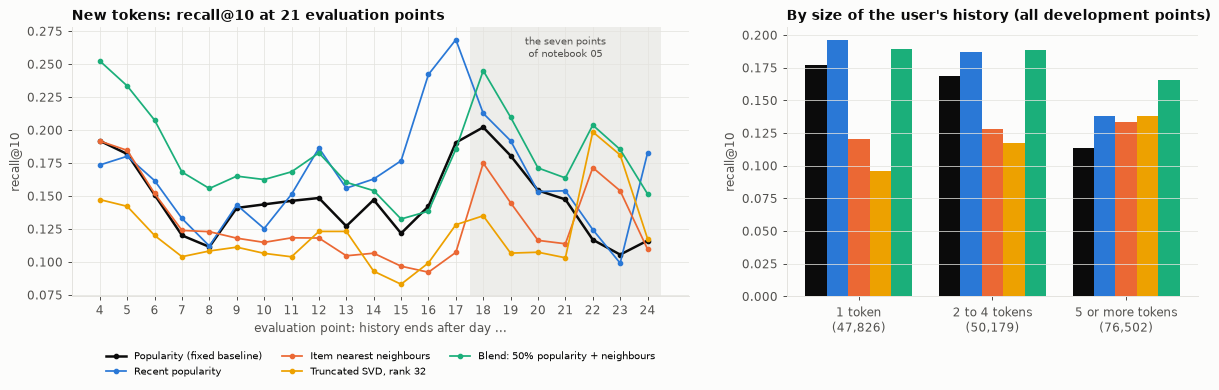

,1 token,2 to 4 tokens,5 or more tokens
Popularity (fixed baseline),0.177,0.169,0.114
Recent popularity,0.196,0.187,0.138
Item nearest neighbours,0.121,0.128,0.134
"Truncated SVD, rank 32",0.096,0.117,0.138
Blend: 50% popularity + neighbours,0.190,0.189,0.166
user evaluations,"47,826.000","50,179.000","76,502.000"


In [9]:
shown = ["Popularity (fixed baseline)", "Recent popularity", "Item nearest neighbours", "Truncated SVD, rank 32", "Blend: 50% popularity + neighbours"]
colors = [INK, BLUE, ORANGE, YELLOW, AQUA]
bounds = [(1, 1, "1 token"), (2, 4, "2 to 4 tokens"), (5, 10**9, "5 or more tokens")]
by_history = {}
for name in shown:
    frame = pd.concat(pooled[name])
    by_history[name] = {label: frame.loc[(frame["n_history"] >= low) & (frame["n_history"] <= high), "recall"].mean() for low, high, label in bounds}
by_history = pd.DataFrame(by_history).T
sizes = pd.concat(pooled[shown[0]])["n_history"]
by_history.loc["user evaluations"] = [int(((sizes >= low) & (sizes <= high)).sum()) for low, high, _ in bounds]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5), gridspec_kw={"width_ratios": [1.5, 1]})
days = [day_of(o) for o in DEV_ORIGINS]
axes[0].axvspan(17.5, 24.5, color=GRID, alpha=0.6, linewidth=0)
axes[0].annotate("the seven points\nof notebook 05", (21, 0.97), xycoords=("data", "axes fraction"), ha="center", va="top", color=MUTED, fontsize=8)
for name, color in zip(shown, colors):
    axes[0].plot(days, per_point.loc[name].to_numpy(), color=color, marker="o", markersize=3.5, label=name, linewidth=2 if "fixed" in name else 1.4)
axes[0].set_xlabel("evaluation point: history ends after day ..."); axes[0].set_ylabel("recall@10"); axes[0].set_xticks(days)
axes[0].set_title("New tokens: recall@10 at 21 evaluation points"); axes[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)

width = 0.16
for i, (name, color) in enumerate(zip(shown, colors)):
    axes[1].bar(np.arange(3) + (i - 2) * width, by_history.loc[name].astype(float), width=width, color=color)
axes[1].set_xticks(np.arange(3)); axes[1].set_xticklabels([f"{label}\n({int(n):,})" for label, n in by_history.loc["user evaluations"].items()])
axes[1].set_ylabel("recall@10"); axes[1].set_title("By size of the user's history (all development points)"); axes[1].grid(axis="x", visible=False)
fig.tight_layout(); plt.show()
by_history

In [10]:
# Does a longer history help? The seven points of notebook 05, with the history starting where that
# notebook started (4 to 10 days) and with the full history (18 to 24 days).
def compare(make_setup, keep_users=None, origins=DEV_ORIGINS):
    rows = []
    for origin in origins:
        setup = make_setup(origin)
        task = setup["task"]
        if keep_users is not None:
            task = {**task, "eval_users": keep_users(task)}
        popularity, knn = pr.Popularity().fit(task["history"]), pr.ItemKNN(k=50, shrink=10).fit(task["history"])
        users = task["eval_users"]
        rows.append({"users per point": len(users), "items": len(task["items"]),
                     "new pairs per point": task["new"][users].sum() + task["cold_new"][users].sum(),
                     "Popularity": pr.evaluate(popularity, task, K)["recall"].mean(),
                     "Item nearest neighbours": pr.evaluate(knn, task, K)["recall"].mean(),
                     "Blend: 50% popularity + neighbours": pr.evaluate(pr.Blend(popularity, knn, 0.5), task, K)["recall"].mean()})
    return pd.DataFrame(rows).mean()

start = time.time()
lengths = pd.DataFrame({
    "History from day 15 (as in notebook 05)": compare(lambda o: make_task(o, history_start=FIRST_STUDY_START), origins=SEEN_ORIGINS),
    "History from day 1 (this notebook)": compare(lambda o: setups[o], origins=SEEN_ORIGINS),
}).T
print(f"mean over the seven points of notebook 05   ({time.time() - start:.0f}s)")
lengths

mean over the seven points of notebook 05   (52s)


,users per point,items,new pairs per point,Popularity,Item nearest neighbours,Blend: 50% popularity + neighbours
History from day 15 (as in notebook 05),"7,559.429","12,914.000","25,684.000",0.155,0.158,0.207
History from day 1 (this notebook),"8,436.286","26,887.143","22,540.429",0.146,0.141,0.190


In [11]:
# Robustness: the same comparison under three changes, averaged over the development points.
def without_largest(task):
    sizes = np.asarray(task["history"].sum(axis=1)).ravel()[task["eval_users"]]
    return task["eval_users"][sizes <= np.quantile(sizes, 0.95)]

start = time.time()
variants = pd.DataFrame({
    "Tokens, buys and sells (main)": compare(lambda o: setups[o]),
    "Tokens, only first-time buys as target": compare(lambda o: make_task(o, future_side="buy")),
    "Tokens, without the 5% of users with the largest histories": compare(lambda o: setups[o], keep_users=without_largest),
    "Pools as items (the idea as first written)": compare(lambda o: make_task(o, frame=events, item="pool")),
}).T
print(f"mean recall@10 over the 21 development points   ({time.time() - start:.0f}s)")
variants

mean recall@10 over the 21 development points   (507s)


,users per point,items,new pairs per point,Popularity,Item nearest neighbours,Blend: 50% popularity + neighbours
"Tokens, buys and sells (main)","8,309.857","21,468.476","26,447.476",0.147,0.130,0.181
"Tokens, only first-time buys as target","6,069.286","21,468.476","16,293.810",0.138,0.121,0.171
"Tokens, without the 5% of users with the largest histories","7,899.143","21,468.476","18,468.286",0.153,0.135,0.188
Pools as items (the idea as first written),"12,666.048","27,052.952","49,024.048",0.242,0.188,0.264


**Reading the results.**

- **The main result holds: popularity blended with nearest neighbours beats popularity.** The equal blend
  scores 0.181 against 0.147 and is ahead at 19 of 21 points. On the 14 points never scored before it is
  ahead at 12, by 0.029 on average, with a 95% interval of 0.018 to 0.040 over points. Its two losses are
  small (0.005 at most).
- **The gain is smaller than two weeks suggested:** +0.034 in place of +0.051, about a quarter above the
  baseline in place of a third.
- **The cautious blend never loses.** 85% popularity with 15% neighbours is ahead at all 21 points, by 0.019
  on average.
- **Nearest neighbours alone do not match popularity.** They score 0.130 and are ahead at 6 of 21 points.
  Notebook 05 found them level. Truncated SVD is lower still (0.121) and loses at all 14 new points.
- **A longer history hurts the models as they are.** At the seven points of notebook 05, going from 4 to
  10 days of history to 18 to 24 days lowers popularity (0.155 to 0.146), nearest neighbours (0.158 to
  0.141) and the blend (0.207 to 0.190). The first row reproduces notebook 05 exactly. Part of the drop is
  a harder target, since fewer tokens are new to a user with a longer history. The rest is that every
  model here weights a trade from three weeks ago like one from yesterday.
- **The best average belongs to a model notebook 05 did not favour:** recent popularity blended with
  neighbours, 0.186 and ahead at 20 of 21 points. Together with the two previous items this says the same
  thing three times: **recency is the missing ingredient.**
- **History size:** the collaborative models still gain with more history and popularity still loses. The
  blend is ahead of popularity in every group, most clearly for users with five or more tokens (0.166
  against 0.114). For users with one token, recent popularity is as good as the blend.
- **The variants agree.** With first-time buys only as the target, without the users with the largest
  histories, and with pools as items, the order is the same: blend, then popularity, then neighbours.

**What the test of significance can and cannot say.** The targets of neighbouring points overlap by a day,
so the 21 points are not independent. On the 11 points with separate targets the equal blend is ahead at
10 (sign test p = 0.012). Recent popularity alone is ahead at 8 of those 11 (p = 0.23), so its advantage
is real on average and not consistent.

## 6. Summary

| Question | Answer |
| --- | --- |
| Does the baseline level hold? | Yes: 0.147 on 21 points, 0.148 on the 14 new ones, against 0.155 before. |
| Does the blend still beat it? | Yes, at 19 of 21 points, by 0.034 on average in place of 0.051. |
| Does collaborative filtering alone match popularity? | No. That was an accident of the seven points. |
| What is new? | Recency matters: recent popularity beats all-time popularity, and a longer unweighted history lowers every score. |
| What follows for the project? | Keep the fixed baseline and report recent popularity next to it; weight or limit the history by time before tuning anything else; expect a gain of about 0.03, not 0.05. |